<a href="https://colab.research.google.com/github/Reemahru/FoodDeliveryOperations/blob/main/Food_Delivery_Data_Challenge_Student_ADVANCED_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚚 Data Challenge — Last-Mile Food Delivery Operations
## EDA + Data Quality + Feature Engineering + Leakage Awareness

### Business Scenario
You are working with the **Operations Analytics Team** of a food-delivery platform.

The company wants to understand why some orders are delivered late and prepare a clean dataset for a future Machine Learning model.

Each row represents **one delivery order**.

### Prediction Moment
Assume the future model would make a prediction:

> **Immediately after the order is accepted and a courier is assigned — before the delivery is completed.**

This prediction moment matters because some fields may not be available yet.

### Target
`late_delivery`

- `1` → Late delivery
- `0` → On-time delivery

### Your Mission
By the end of this challenge, you should produce:

1. A structured EDA
2. A data-quality report
3. A cleaned dataset
4. At least **8 engineered features**
5. A leakage audit
6. A final model-ready feature table
7. A short executive summary

### Time
Suggested: **90–120 minutes**


# Dataset Dictionary

| Column | Meaning |
|---|---|
| `order_id` | Unique order identifier |
| `order_date` | Date when the order was placed |
| `order_hour` | Hour of day when the order was placed |
| `city` | Delivery city |
| `delivery_zone` | Delivery zone within the city |
| `distance_km` | Approximate delivery distance |
| `order_value_sar` | Total order value in SAR |
| `item_count` | Number of items in the order |
| `estimated_prep_min` | Restaurant estimated preparation time |
| `courier_experience_months` | Courier experience on the platform |
| `vehicle_type` | Courier vehicle type |
| `weather` | Weather condition |
| `traffic_level` | Traffic level |
| `is_weekend` | Whether the order happened on a weekend |
| `promo_used` | Whether a promotion was used |
| `estimated_delivery_min` | Platform estimated delivery time |
| `actual_delivery_min` | Actual delivery time after completion |
| `customer_rating` | Customer rating after delivery |
| `late_reason` | Reason recorded for late delivery |
| `late_delivery` | Target variable |

> Important: The dataset comes from an operational system.  
> Do not assume that every value is correct or every column is safe for modeling.


# Challenge Rules

### Rule 1
Do not clean the data immediately.

First **inspect, document, and justify**.

### Rule 2
Every important transformation must have a reason.

### Rule 3
Do not create Features just to increase the number of columns.

### Rule 4
Always think about the **prediction moment**.

### Rule 5
For every important plot, write a short interpretation.

### Rule 6
If you remove rows or columns, document the decision.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

DATA_PATH = "food_delivery_operations_challenge.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded.")
print("Shape:", df.shape)
df.head()


Dataset loaded.
Shape: (862, 20)


,order_id,order_date,order_hour,city,delivery_zone,distance_km,order_value_sar,item_count,estimated_prep_min,courier_experience_months,vehicle_type,weather,traffic_level,is_weekend,promo_used,estimated_delivery_min,actual_delivery_min,customer_rating,late_reason,late_delivery
0,ORD00570,2026-09-16,22,Jeddah,Central,3.92,30.41,4,13.4,4.0,Motorbike,Clear,High,No,no,33.8,35.8,4.5,NaN,0
1,ORD00295,2026-08-16,20,Dammam,Central,4.15,73.00,3,20.0,46.0,Motorbike,Hot,Medium,No,No,37.1,39.8,5.0,NaN,0
2,ORD00831,2026-09-20,20,RIYADH,East,4.21,61.06,45,13.2,12.0,Car,Clear,Low,No,No,28.1,26.5,3.7,NaN,0
3,ORD00259,2026-09-04,12,Dammam,Central,3.88,77.74,2,10.3,8.0,Car,Rainy,Medium,Yes,No,30.3,38.5,2.8,Traffic congestion,1
4,ORD00013,2026-10-26,21,Riyadh,East,8.11,159.24,9,33.5,4.0,Motorbike,Clear,High,No,Yes,62.6,55.2,4.0,NaN,0


# SECTION 1 — Data Understanding

Before changing anything, understand the structure.

## Task 1.1 — Dataset Profile

Answer:

- How many rows?<br>
862 rows
- How many columns?<br>
20 columns
- What does one row represent?<br>
delivery order
- What is the target?<br>
`late_delivery`
- What is the target balance?<br>
Balanced 436 late orders (50.6%) vs 426 on time orders (49.4%)
- Which columns are numerical?<br>
`order_hour`, `distance_km`, `order_value_sar`, `item_count`, `estimated_prep_min`, `courier_experience_months`, `estimated_delivery_min`, `actual_delivery_min`, `customer_rating`
- Which are categorical?<br>
`city`, `delivery_zone`, `vehicle_type`, `weather`, `traffic_level`, `is_weekend`, `promo_used`, `late_reason`
- Which should be dates?<br>
`order_date`
- Which column is an identifier?<br>
`order_id` <br>
Create a small **dataset profile**.


In [ ]:
# TODO 1.1
# Inspect:
# - shape
print(df.shape)
# - dtypes
print("\nData type :")
print(df.dtypes)
# - head
print("\nFirst five records :")
display(df.head())
# - tail
print("\nLast five records :")
display(df.tail())
# - missing values
print("\nMissing values :")
print(df.isna().sum())
# - duplicate rows
print("\nDuplicate rows :")
print(df.duplicated().sum())
# - unique counts
print("\nUnique values :")
print(df.nunique())
# - target distribution
print("\nTarget distribution :")
print(df["late_delivery"].value_counts())
print((df["late_delivery"].value_counts(normalize=True) * 100).round(1))


(862, 20)

Data type :
order_id                      object
order_date                    object
order_hour                     int64
city                          object
delivery_zone                 object
distance_km                  float64
order_value_sar              float64
item_count                     int64
estimated_prep_min           float64
courier_experience_months    float64
vehicle_type                  object
weather                       object
traffic_level                 object
is_weekend                    object
promo_used                    object
estimated_delivery_min       float64
actual_delivery_min          float64
customer_rating              float64
late_reason                   object
late_delivery                  int64
dtype: object

First five records :


,order_id,order_date,order_hour,city,delivery_zone,distance_km,order_value_sar,item_count,estimated_prep_min,courier_experience_months,vehicle_type,weather,traffic_level,is_weekend,promo_used,estimated_delivery_min,actual_delivery_min,customer_rating,late_reason,late_delivery
0,ORD00570,2026-09-16,22,Jeddah,Central,3.92,30.41,4,13.4,4.0,Motorbike,Clear,High,No,no,33.8,35.8,4.5,NaN,0
1,ORD00295,2026-08-16,20,Dammam,Central,4.15,73.00,3,20.0,46.0,Motorbike,Hot,Medium,No,No,37.1,39.8,5.0,NaN,0
2,ORD00831,2026-09-20,20,RIYADH,East,4.21,61.06,45,13.2,12.0,Car,Clear,Low,No,No,28.1,26.5,3.7,NaN,0
3,ORD00259,2026-09-04,12,Dammam,Central,3.88,77.74,2,10.3,8.0,Car,Rainy,Medium,Yes,No,30.3,38.5,2.8,Traffic congestion,1
4,ORD00013,2026-10-26,21,Riyadh,East,8.11,159.24,9,33.5,4.0,Motorbike,Clear,High,No,Yes,62.6,55.2,4.0,NaN,0



Last five records :


,order_id,order_date,order_hour,city,delivery_zone,distance_km,order_value_sar,item_count,estimated_prep_min,courier_experience_months,vehicle_type,weather,traffic_level,is_weekend,promo_used,estimated_delivery_min,actual_delivery_min,customer_rating,late_reason,late_delivery
857,ORD00287,2026-07-17,22,Jeddah,Central,3.50,120.87,4,17.9,9.0,Motorbike,Hot,Medium,Yes,Yes,33.7,40.6,3.4,Restaurant delay,1
858,ORD00831,2026-09-20,20,RIYADH,East,4.21,61.06,45,13.2,12.0,Car,Clear,Low,No,No,28.1,26.5,3.7,NaN,0
859,ORD00618,2026-10-01,21,MADINAH,North,3.84,115.13,5,22.3,14.0,Car,Hot,Low,No,Yes,36.9,42.2,3.8,Restaurant delay,1
860,ORD00711,2026-08-01,20,Riyadh,Central,6.34,54.32,4,21.0,33.0,Motorbike,Clear,Medium,Yes,Yes,42.2,46.2,5.0,NaN,0
861,ORD00420,2026-10-26,22,Dammam,Central,NaN,52.12,6,22.1,6.0,Motorbike,Rainy,Medium,No,No,38.6,45.5,2.7,Restaurant delay,1



Missing values :
order_id                       0
order_date                     0
order_hour                     0
city                           0
delivery_zone                  0
distance_km                   34
order_value_sar                0
item_count                     0
estimated_prep_min             0
courier_experience_months     29
vehicle_type                   0
weather                       19
traffic_level                  0
is_weekend                     0
promo_used                     0
estimated_delivery_min         0
actual_delivery_min            0
customer_rating               22
late_reason                  426
late_delivery                  0
dtype: int64

Duplicate rows :
12

Unique values :
order_id                     850
order_date                   123
order_hour                    17
city                          19
delivery_zone                  5
distance_km                  576
order_value_sar              824
item_count                    13
estimat

In [ ]:
# TODO 1.2 — Create a structured column profile

column_profile = pd.DataFrame({
    "dtype": df.dtypes,
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100,
    "n_unique": df.nunique(dropna=False)
})

column_profile


,dtype,missing_count,missing_pct,n_unique
order_id,object,0,0.000000,850
order_date,object,0,0.000000,123
order_hour,int64,0,0.000000,17
city,object,0,0.000000,19
delivery_zone,object,0,0.000000,5
distance_km,float64,34,3.944316,577
order_value_sar,float64,0,0.000000,824
item_count,int64,0,0.000000,13
estimated_prep_min,float64,0,0.000000,236
courier_experience_months,float64,29,3.364269,63


## Interpretation Checkpoint

Write 4–6 sentences:

- What looks normal?<br>
The dataset has 862 rows and 20 columns. each row is one delivery order. Most columns have no missing values, and the column types are mostly as expected (10 text, 7 float, 3 integer).
- What immediately looks suspicious? <br>
`order_id` has only 850 unique values for 862 rows, which suggests duplicate orders. Several categorical columns have far more unique values than expected: city has 19 labels for 5 cities, traffic_level has 12 instead of 3, and promo_used has 8 instead of 2 pointing to inconsistent spelling or formatting.
- Which columns deserve closer inspection?<br>
`order_id`, `city`, `traffic_level` and `promo_used `because of their unexpected unique counts, and `order_date`, which is stored as text and must be converted to a date.
- Is the target balanced or imbalanced?<br>
The target is balanced 436 late orders (50.6%) vs 426 on time orders (49.4%).

# SECTION 2 — Data Quality Audit

You are now the **data quality investigator**.

Your job is not only to find problems, but also to decide whether they are:

- Valid
- Invalid
- Suspicious
- Missing
- Inconsistent
- Potentially dangerous for modeling


## Task 2.1 — Missing Values

For every column with missing values:

1. Count missing values
2. Calculate missing percentage
3. Decide whether missingness is acceptable
4. Propose an action

Do not impute yet.


In [ ]:
# TODO 2.1

missing_report = (
    pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_pct": df.isna().mean() * 100
    })
    .query("missing_count > 0")
    .sort_values("missing_pct", ascending=False)
)
acceptable = {
    "late_reason": "yes because on-time orders don't have a late reason, so it's normal to be empty",
    "distance_km": "yes, it's small (4%) so that's okay",
    "courier_experience_months": "yes, it's small (3%) so that's okay",
    "customer_rating": "yes acceptable, not all customers rate",
    "weather": "yes, it's small (2%) so that's okay",
}

action = {
    "late_reason": "Drop column (leakage)",
    "distance_km": "Fill with city median + missing flag",
    "courier_experience_months": "Fill with median + missing flag",
    "customer_rating": "Drop column (leakage)",
    "weather": "Fill with 'Unknown' category",
}

missing_report["acceptable"] = missing_report.index.map(acceptable)
missing_report["proposed_action"] = missing_report.index.map(action)
missing_report


,missing_count,missing_pct,acceptable,proposed_action
late_reason,426,49.419954,yes because on-time orders don't have a late r...,Drop column (leakage)
distance_km,34,3.944316,"yes, it's small (4%) so that's okay",Fill with city median + missing flag
courier_experience_months,29,3.364269,"yes, it's small (3%) so that's okay",Fill with median + missing flag
customer_rating,22,2.552204,"yes acceptable, not all customers rate",Drop column (leakage)
weather,19,2.204176,"yes, it's small (2%) so that's okay",Fill with 'Unknown' category


## Task 2.2 — Duplicate Investigation

Check:

- Exact duplicate rows
- Duplicate `order_id`
- Whether duplicates appear accidental or meaningful


In [ ]:
# TODO 2.2
exact_duplicate_count = int(df.duplicated().sum())
duplicate_id_count = int(df["order_id"].duplicated(keep=False).sum())
duplicate_id_values = df.loc[df["order_id"].duplicated(keep=False), "order_id"].value_counts()
print("Exact duplicate rows:", exact_duplicate_count)
print("Rows belonging to duplicated order IDs:", duplicate_id_count)
print("Number of duplicated order IDs:", int(df["order_id"].duplicated().sum()))
display(duplicate_id_values.rename("row_count").to_frame())
print("Inspection of duplicate-ID rows:")
display(df[df["order_id"].isin(duplicate_id_values.index)].sort_values("order_id"))
print("Interpretation: all 12 repeated order IDs are exact duplicate rows in this file; keep one copy of each.")


Exact duplicate rows: 12
Rows belonging to duplicated order IDs: 24
Number of duplicated order IDs: 12


,row_count
order_id,
ORD00831,2
ORD00756,2
ORD00470,2
ORD00226,2
ORD00307,2
ORD00588,2
ORD00379,2
ORD00627,2
ORD00714,2


Inspection of duplicate-ID rows:


,order_id,order_date,order_hour,city,delivery_zone,distance_km,order_value_sar,item_count,estimated_prep_min,courier_experience_months,vehicle_type,weather,traffic_level,is_weekend,promo_used,estimated_delivery_min,actual_delivery_min,customer_rating,late_reason,late_delivery
346,ORD00226,2026-08-23,12,Jeddah,Central,0.50,46.03,3,23.8,9.0,Car,Clear,High,No,No,38.2,38.7,4.5,NaN,0
108,ORD00226,2026-08-23,12,Jeddah,Central,0.50,46.03,3,23.8,9.0,Car,Clear,High,No,No,38.2,38.7,4.5,NaN,0
611,ORD00247,2026-07-17,20,Riyadh,North,1.49,63.41,6,25.2,4.0,Car,Clear,Medium,Yes,Yes,37.5,42.8,4.4,Courier delay,1
826,ORD00247,2026-07-17,20,Riyadh,North,1.49,63.41,6,25.2,4.0,Car,Clear,Medium,Yes,Yes,37.5,42.8,4.4,Courier delay,1
181,ORD00307,2026-09-06,22,Riyadh,Central,2.34,62.87,8,25.2,3.0,Car,Clear,High,No,Yes,43.5,48.0,4.2,NaN,0
526,ORD00307,2026-09-06,22,Riyadh,Central,2.34,62.87,8,25.2,3.0,Car,Clear,High,No,Yes,43.5,48.0,4.2,NaN,0
726,ORD00379,2026-09-18,20,Riyadh,Central,7.31,170.53,6,17.1,7.0,Car,Clear,High,Yes,No,45.8,62.1,4.6,Traffic congestion,1
220,ORD00379,2026-09-18,20,Riyadh,Central,7.31,170.53,6,17.1,7.0,Car,Clear,High,Yes,No,45.8,62.1,4.6,Traffic congestion,1
38,ORD00470,2026-07-07,12,Riyadh,North,8.72,48.33,5,21.9,9.0,Motorbike,Rainy,High,No,No,55.2,65.5,4.2,Restaurant delay,1
58,ORD00470,2026-07-07,12,Riyadh,North,8.72,48.33,5,21.9,9.0,Motorbike,Rainy,High,No,No,55.2,65.5,4.2,Restaurant delay,1


Interpretation: all 12 repeated order IDs are exact duplicate rows in this file; keep one copy of each.


## Task 2.3 — Numerical Validity Checks

Investigate at minimum:

- `distance_km`
- `order_value_sar`
- `item_count`
- `order_hour`
- `estimated_prep_min`
- `courier_experience_months`
- `estimated_delivery_min`
- `actual_delivery_min`
- `customer_rating`

For each one ask:

> What values are impossible?  
> What values are unusual but still possible?


Invalid values:
distance_km : 2
order_value_sar : 1
item_count : 2
order_hour : 3
estimated_prep_min : 0
courier_experience_months : 0
estimated_delivery_min : 1
actual_delivery_min : 0
customer_rating : 22

unusual values:
distance_km: range [-3.6, 13.1] → 29 unusual
order_value_sar: range [-33.5, 202.3] → 38 unusual
item_count: range [-1.5, 10.5] → 3 unusual
order_hour: range [5.6, 28.6] → 2 unusual
estimated_prep_min: range [7.5, 35.4] → 10 unusual
courier_experience_months: range [-12.0, 44.0] → 33 unusual
estimated_delivery_min: range [18.1, 64.8] → 21 unusual
actual_delivery_min: range [14.8, 79.4] → 16 unusual
customer_rating: range [2.0, 6.0] → 0 unusual


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
distance_km,828.0,5.311630,4.677635,-3.2,0.5054,1.0470,2.6700,4.44,6.8250,12.001,18.1057,92.0
order_value_sar,862.0,116.005406,519.711738,-15.0,21.2118,30.5645,54.9275,78.40,113.8675,190.652,310.7096,12000.0
item_count,862.0,4.523202,3.278239,0.0,1.0000,2.0000,3.0000,4.00,6.0000,8.000,10.0000,60.0
order_hour,862.0,17.531323,3.686724,-1.0,10.0000,11.0000,14.2500,19.00,20.0000,22.000,23.0000,30.0
estimated_prep_min,862.0,21.432367,5.363039,7.2,9.5610,12.5000,18.0000,21.50,24.9750,30.595,35.2390,41.0
courier_experience_months,833.0,17.164466,11.944607,0.0,1.0000,3.0000,9.0000,15.00,23.0000,40.400,57.6800,72.0
estimated_delivery_min,862.0,42.177842,11.747836,-10.0,23.0880,28.3000,35.6000,41.10,47.3000,58.895,69.3340,240.0
actual_delivery_min,862.0,48.058585,15.403119,12.0,21.3610,28.8050,39.0250,46.50,55.1750,68.695,86.1670,223.1
customer_rating,840.0,3.989881,0.670353,2.1,2.5000,2.9000,3.5000,4.00,4.5000,5.000,5.0000,5.0


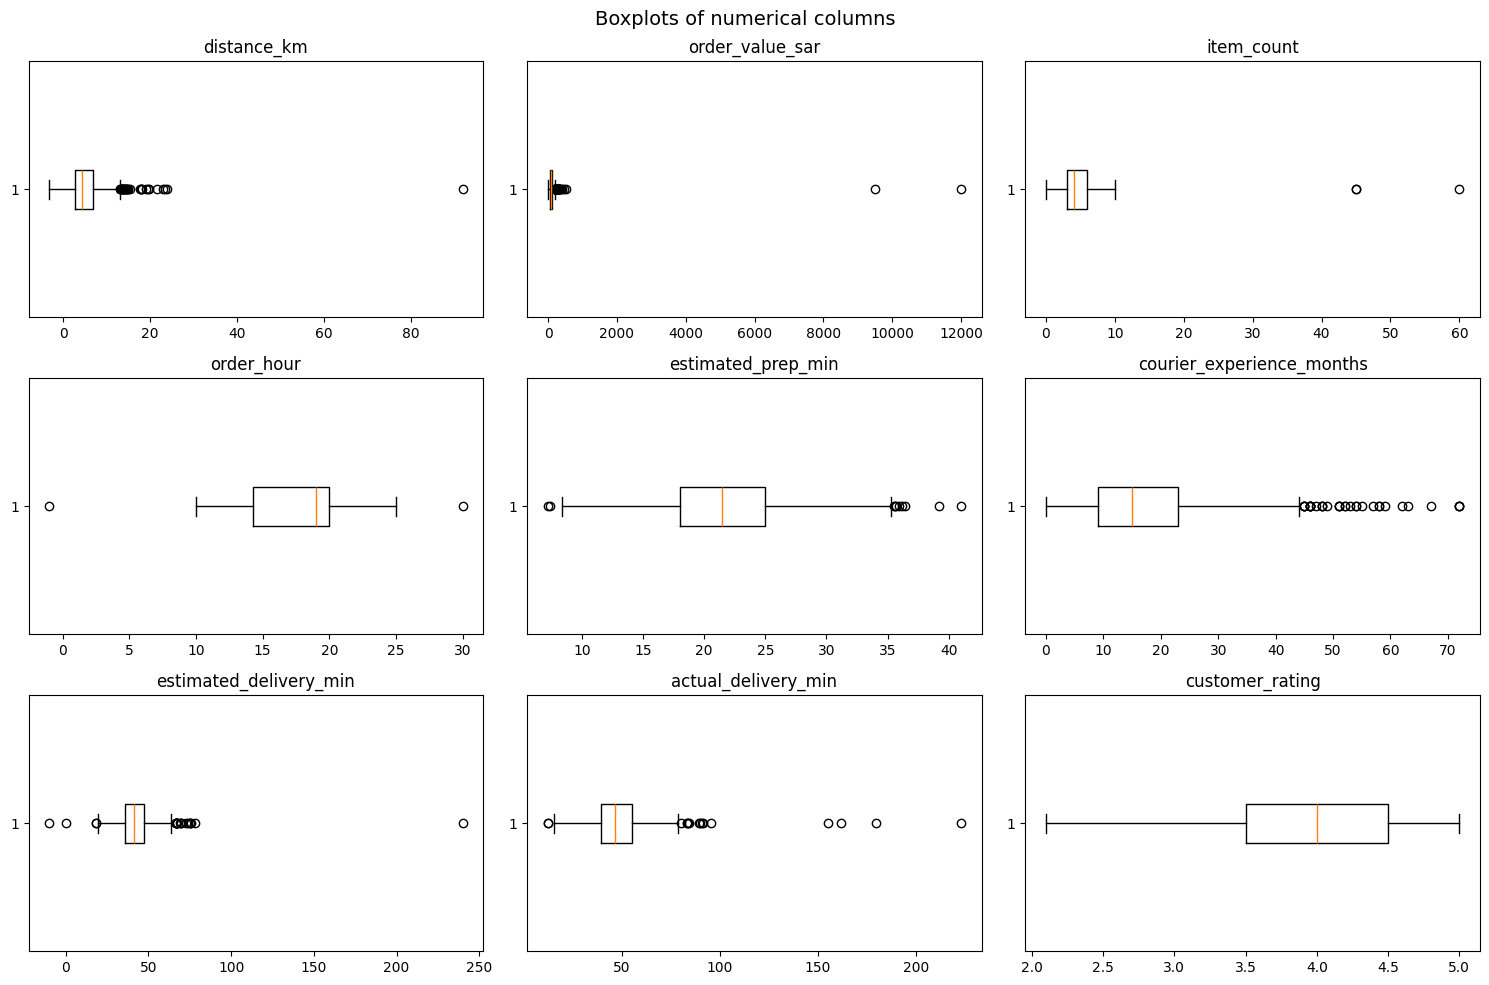

In [ ]:
# TODO 2.3
# Use min/max, quantiles, boxplots, or custom conditions.

numeric_cols = [
    "distance_km",
    "order_value_sar",
    "item_count",
    "order_hour",
    "estimated_prep_min",
    "courier_experience_months",
    "estimated_delivery_min",
    "actual_delivery_min",
    "customer_rating"
]

invalid_values = {
    "distance_km": df["distance_km"] < 0,
    "order_value_sar": df["order_value_sar"] < 0,
    "item_count": df["item_count"] <= 0,
    "order_hour": ~df["order_hour"].between(0, 23),
    "estimated_prep_min": df["estimated_prep_min"] < 0,
    "courier_experience_months": df["courier_experience_months"] < 0,
    "estimated_delivery_min": df["estimated_delivery_min"] < 0,
    "actual_delivery_min": df["actual_delivery_min"] < 0,
    "customer_rating": ~df["customer_rating"].between(1, 5)
}
print("Invalid values:")
for column, condition in invalid_values.items():
    print(column, ":", condition.sum())

print("\nunusual values:")
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = df[(df[col] < low) | (df[col] > high)][col]
    print(f"{col}: range [{low:.1f}, {high:.1f}] → {len(outliers)} unusual")

display(df[numeric_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T)

# Boxplots
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.flat, numeric_cols):
    ax.boxplot(df[col].dropna(), vert=False)
    ax.set_title(col)
plt.suptitle("Boxplots of numerical columns", fontsize=14)
plt.tight_layout()
plt.show()


## Task 2.4 — Categorical Consistency

Inspect:

- `city`
- `delivery_zone`
- `vehicle_type`
- `weather`
- `traffic_level`
- `is_weekend`
- `promo_used`

Look for:
- different capitalization
- leading/trailing spaces
- duplicate meanings
- rare categories


In [ ]:
# TODO 2.4

categorical_cols = [
    "city",
    "delivery_zone",
    "vehicle_type",
    "weather",
    "traffic_level",
    "is_weekend",
    "promo_used"
]

for col in categorical_cols:
    print("\nCOLUMN:", col)
    print(df[col].value_counts(dropna=False))
summary = []
for col in categorical_cols:
    s = df[col].dropna()
    summary.append({
        "Column": col,
        "Unique values now": s.nunique(),
        "Unique if case & spaces fixed": s.str.strip().str.lower().nunique(),
        "Rows with extra spaces": (s != s.str.strip()).sum(),
        "Rare values (<1% of rows)": (s.value_counts(normalize=True) < 0.01).sum(),
    })
pd.DataFrame(summary)


COLUMN: city
city
Riyadh        363
Jeddah        199
Dammam        102
Madinah        79
Abha           74
riyadh          7
Al Madinah      5
jeddah          5
RIYADH          4
 Jeddah         4
Riyadh          4
JEDDAH          3
ABHA            3
DAMMAM          2
Dammam          2
dammam          2
madinah         2
Abha            1
MADINAH         1
Name: count, dtype: int64

COLUMN: delivery_zone
delivery_zone
Central    244
North      223
South      199
East       123
West        73
Name: count, dtype: int64

COLUMN: vehicle_type
vehicle_type
Motorbike    451
Car          330
Bicycle       81
Name: count, dtype: int64

COLUMN: weather
weather
Clear    440
Hot      206
Windy     73
Dusty     67
Rainy     57
NaN       19
Name: count, dtype: int64

COLUMN: traffic_level
traffic_level
Medium     322
High       262
Low        246
High         8
MEDIUM       6
HIGH         5
LOW          4
Low          3
medium       3
high         1
low          1
 Medium      1
Name: count, dtyp

,Column,Unique values now,Unique if case & spaces fixed,Rows with extra spaces,Rare values (<1% of rows)
0,city,19,6,11,14
1,delivery_zone,5,5,0,0
2,vehicle_type,3,3,0,0
3,weather,5,5,0,0
4,traffic_level,12,3,12,9
5,is_weekend,2,2,0,0
6,promo_used,8,4,13,6


## Task 2.5 — Data Quality Report

Build a structured report with at least **8 findings**.

Required columns:

| Issue | Column | Evidence | Severity | Proposed Action | Justification |
|---|---|---|---|---|---|

Suggested severity:
- Low
- Medium
- High


In [ ]:
# TODO 2.5

#quality_findings = []

# Example structure:
# quality_findings.append({
#     "Issue": "...",
#     "Column": "...",
#     "Evidence": "...",
#     "Severity": "High",
#     "Proposed Action": "...",
#     "Justification": "..."
# })
quality_findings = [
    {"Issue":"Missing values","Column":"distance_km","Evidence":f"{df.distance_km.isna().sum()} missing ({df.distance_km.isna().mean():.1%})","Severity":"Medium","Proposed Action":"Keep as missing","Justification":"Distance is important operational information; avoid dropping otherwise useful orders."},
    {"Issue":"Missing values","Column":"courier_experience_months","Evidence":f"{df.courier_experience_months.isna().sum()} missing ({df.courier_experience_months.isna().mean():.1%})","Severity":"Medium","Proposed Action":"Retain missing and add a missingness indicator if modeling benefits.","Justification":"Unknown experience should not be interpreted as zero experience."},
    {"Issue":"Missing values","Column":"weather","Evidence":f"{df.weather.isna().sum()} missing","Severity":"Low","Proposed Action":"Normalize labels and impute as 'Unknown'.","Justification":"Missing weather is a distinct unknown state."},
    {"Issue":"Missing values","Column":"customer_rating","Evidence":f"{df.customer_rating.isna().sum()} missing","Severity":"High","Proposed Action":"Exclude from prediction features because it is post-delivery.","Justification":"Rating is unavailable at the stated prediction moment."},
    {"Issue":"Structural missingness","Column":"late_reason","Evidence":f"{df.late_reason.isna().sum()} missing; compare with on-time count {int((df.late_delivery==0).sum())}","Severity":"High","Proposed Action":"Exclude from model features; retain only for retrospective analysis.","Justification":"A reason is generally recorded only for late orders and reveals outcome information."},
    {"Issue":"Duplicate records","Column":"order_id","Evidence":f"{exact_duplicate_count} exact duplicate rows; {df.order_id.duplicated().sum()} repeated IDs","Severity":"High","Proposed Action":"Drop exact duplicate rows, keeping the first.","Justification":"Duplicates would over-weight repeated deliveries and bias analysis."},
    {"Issue":"Invalid range","Column":"order_hour","Evidence":f"{((df.order_hour<0)|(df.order_hour>23)).sum()} values outside 0–23; min={df.order_hour.min()}, max={df.order_hour.max()}","Severity":"High","Proposed Action":"Set impossible hours to missing; do not guess a replacement.","Justification":"Hour of day must be between 0 and 23."},
    {"Issue":"Invalid range","Column":"distance_km","Evidence":f"{(df.distance_km<0).sum()} negative distances; max={df.distance_km.max()} km","Severity":"High","Proposed Action":"Set negative values to missing; flag very large values for review.","Justification":"Negative distance is impossible; unusually long distance may be valid but needs verification."},
    {"Issue":"Invalid range","Column":"order_value_sar","Evidence":f"{(df.order_value_sar<0).sum()} negative values; max={df.order_value_sar.max()} SAR","Severity":"High","Proposed Action":"Set negative values to missing; inspect extreme positive values.","Justification":"An order total cannot ordinarily be negative; a large value may be a bulk order or data-entry issue."},
    {"Issue":"Invalid range","Column":"item_count","Evidence":f"{(df.item_count<=0).sum()} zero/non-positive item counts; max={df.item_count.max()}","Severity":"High","Proposed Action":"Set non-positive counts to missing; review extreme counts.","Justification":"A completed food order should contain at least one item."},
    {"Issue":"Invalid range","Column":"estimated_delivery_min","Evidence":f"{(df.estimated_delivery_min<=0).sum()} non-positive estimates; min={df.estimated_delivery_min.min()}","Severity":"High","Proposed Action":"Set non-positive values to missing; flag extreme values.","Justification":"A delivery estimate must be positive."},
    {"Issue":"Categorical inconsistency","Column":"city, traffic_level, promo_used","Evidence":"Mixed case, leading/trailing spaces, abbreviations, and 'Al Madinah' variant.","Severity":"Medium","Proposed Action":"Strip whitespace, standardize case, and map known aliases.","Justification":"Equivalent categories should not be counted separately."},
    {"Issue":"Potential target leakage","Column":"actual_delivery_min, customer_rating, late_reason","Evidence":"Recorded after or directly informed by delivery outcome.","Severity":"High","Proposed Action":"Exclude from model-ready predictors.","Justification":"These fields are unavailable at prediction time or reveal the outcome."}
]

quality_report = pd.DataFrame(quality_findings)
quality_report


,Issue,Column,Evidence,Severity,Proposed Action,Justification
0,Missing values,distance_km,34 missing (3.9%),Medium,Keep as missing; impute using training-fold me...,Distance is important operational information;...
1,Missing values,courier_experience_months,29 missing (3.4%),Medium,Retain missing and add a missingness indicator...,Unknown experience should not be interpreted a...
2,Missing values,weather,19 missing,Low,Normalize labels and impute as 'Unknown'.,Missing weather is a distinct unknown state.
3,Missing values,customer_rating,22 missing,High,Exclude from prediction features because it is...,Rating is unavailable at the stated prediction...
4,Structural missingness,late_reason,426 missing; compare with on-time count 426,High,Exclude from model features; retain only for r...,A reason is generally recorded only for late o...
5,Duplicate records,order_id,12 exact duplicate rows; 12 repeated IDs,High,"Drop exact duplicate rows, keeping the first.",Duplicates would over-weight repeated deliveri...
6,Invalid range,order_hour,"3 values outside 0–23; min=-1, max=30",High,Set impossible hours to missing; do not guess ...,Hour of day must be between 0 and 23.
7,Invalid range,distance_km,2 negative distances; max=92.0 km,High,Set negative values to missing; flag very larg...,Negative distance is impossible; unusually lon...
8,Invalid range,order_value_sar,1 negative values; max=12000.0 SAR,High,Set negative values to missing; inspect extrem...,An order total cannot ordinarily be negative; ...
9,Invalid range,item_count,2 zero/non-positive item counts; max=60,High,Set non-positive counts to missing; review ext...,A completed food order should contain at least...


### Checkpoint A

Before continuing, answer:

1. Which problem would you fix first?
2. Which suspicious value would you **not** automatically delete?
3. Which issue could most strongly affect later analysis?


# SECTION 3 — Exploratory Data Analysis

Your EDA should answer operational questions, not just produce charts.

You must create:
- At least **4 univariate analyses**
- At least **4 Feature ↔ Target analyses**
- At least **2 Feature ↔ Feature analyses**


## Task 3.1 — Univariate Analysis

Choose at least:
- 2 numerical variables
- 2 categorical variables

For each:
1. Plot
2. Describe distribution
3. Identify unusual patterns


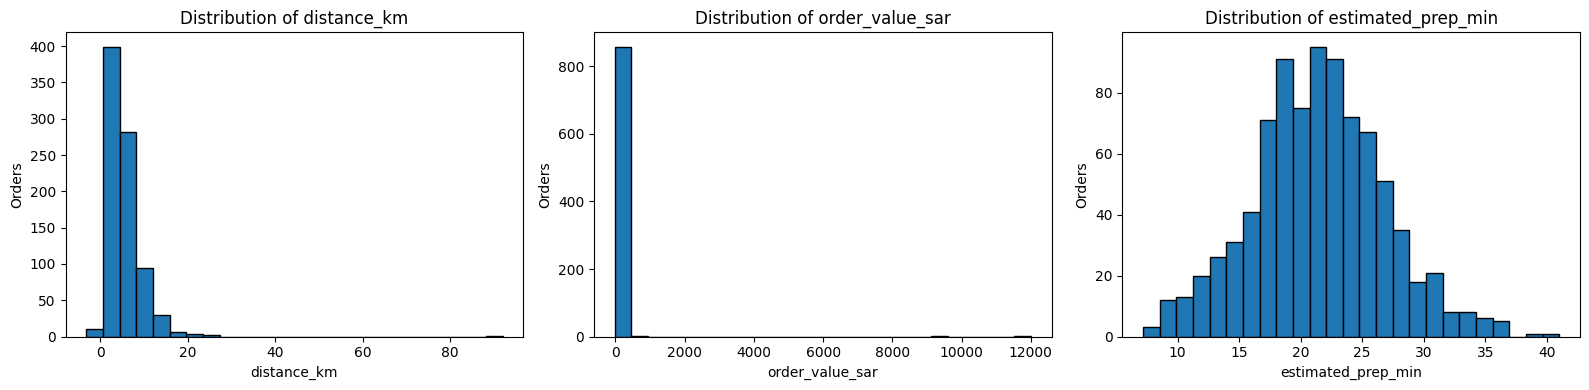

,count,mean,std,min,25%,50%,75%,max
distance_km,828.0,5.311630,4.677635,-3.2,2.6700,4.44,6.8250,92.0
order_value_sar,862.0,116.005406,519.711738,-15.0,54.9275,78.40,113.8675,12000.0
estimated_prep_min,862.0,21.432367,5.363039,7.2,18.0000,21.50,24.9750,41.0


Interpretation: inspect skew and extreme tails before choosing transformations; the unusually large order values and distances warrant review rather than automatic deletion.


In [ ]:
# TODO 3.1 — Numerical distributions
numeric_eda_cols = ["distance_km", "order_value_sar", "estimated_prep_min"]
fig, axes = plt.subplots(1, len(numeric_eda_cols), figsize=(16, 4))
for ax, col in zip(axes, numeric_eda_cols):
    ax.hist(df[col].dropna(), bins=25, edgecolor="black")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Orders")
plt.tight_layout()
plt.show()
display(df[numeric_eda_cols].describe().T)
print("Interpretation: inspect skew and extreme tails before choosing transformations; the unusually large order values and distances warrant review rather than automatic deletion.")

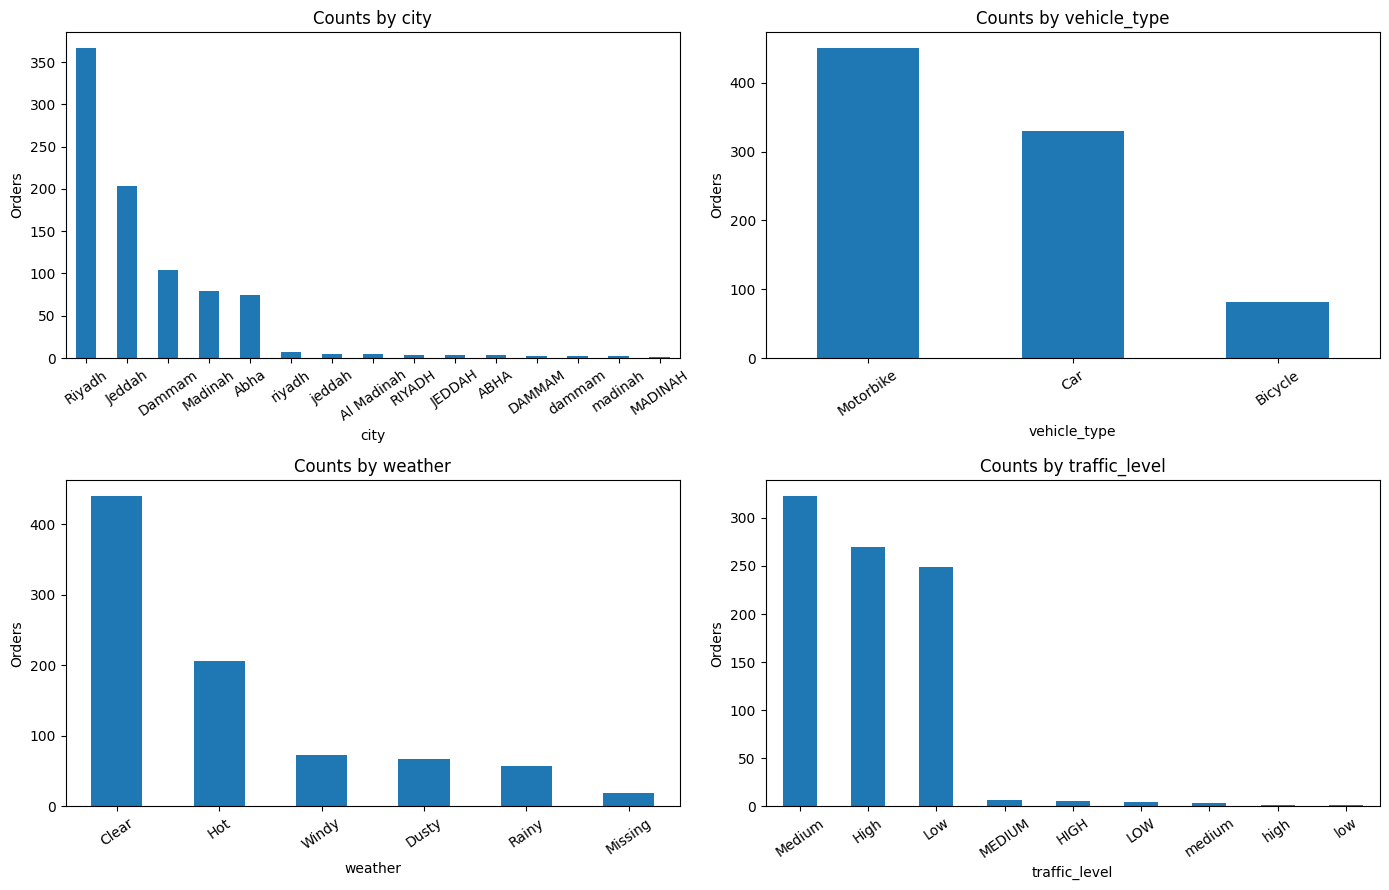

city: 19 observed non-missing categories.
vehicle_type: 3 observed non-missing categories.
weather: 5 observed non-missing categories.
traffic_level: 12 observed non-missing categories.


In [ ]:
# TODO 3.1 — Categorical distributions
categorical_eda_cols = ["city", "vehicle_type", "weather", "traffic_level"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, categorical_eda_cols):
    counts = df[col].fillna("Missing").astype(str).str.strip().value_counts()
    counts.plot(kind="bar", ax=ax)
    ax.set_title(f"Counts by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Orders")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()
for col in categorical_eda_cols:
    print(f"{col}: {df[col].nunique(dropna=True)} observed non-missing categories.")

## Task 3.2 — Target Analysis

Analyze `late_delivery`.

Questions:
- What percentage of orders are late?
- Is the target balanced?
- Would Accuracy alone be enough later?

No model training is required.


,Orders,Percent %
On-time (0),426,49.4
Late (1),436,50.6


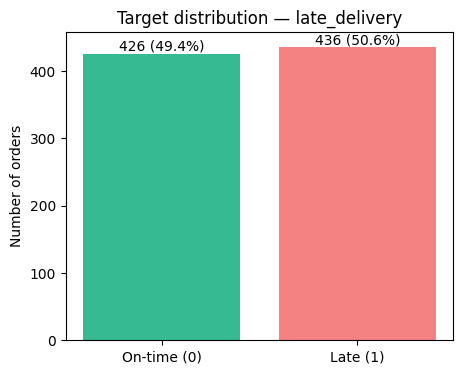

In [ ]:
# TODO 3.2
counts = df["late_delivery"].value_counts().sort_index()
pct = df["late_delivery"].value_counts(normalize=True).sort_index().mul(100).round(1)

target_table = pd.DataFrame({"Orders": counts, "Percent %": pct})
target_table.index = ["On-time (0)", "Late (1)"]
display(target_table)

plt.figure(figsize=(5, 4))
bars = plt.bar(target_table.index, target_table["Orders"], color=["#36BA91", "#F48283"])
for bar, n, p in zip(bars, target_table["Orders"], target_table["Percent %"]):
    plt.text(bar.get_x() + bar.get_width() / 2, n, f"{n} ({p}%)", ha="center", va="bottom")
plt.title("Target distribution — late_delivery")
plt.ylabel("Number of orders")
plt.show()

## Task 3.3 — Feature ↔ Target Relationships

Investigate at least 4 questions.

Possible directions:

- Does lateness increase with distance?
- Does traffic level affect late deliveries?
- Does courier experience matter?
- Does weather matter?
- Are peak hours different?
- Does vehicle type matter?
- Does estimated preparation time matter?


,Orders,Late_orders,Late_rate
vehicle_type,,,
Bicycle,81,55,67.9
Car,330,204,61.8
Motorbike,451,177,39.2


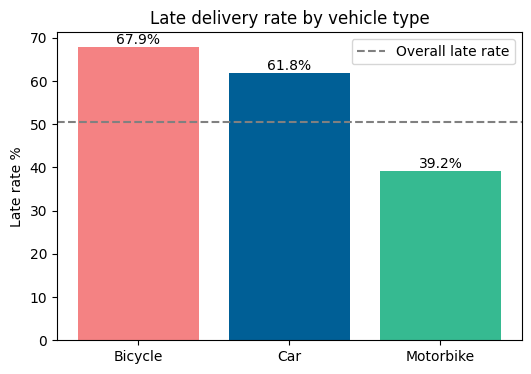

In [ ]:
# TODO 3.3 — Relationship 1
vehicle = df.groupby("vehicle_type")["late_delivery"].agg(
    Orders="size",
    Late_orders="sum",
    Late_rate="mean"
)
vehicle["Late_rate"] = (vehicle["Late_rate"] * 100).round(1)
vehicle = vehicle.sort_values("Late_rate", ascending=False)
display(vehicle)

plt.figure(figsize=(6, 4))
bars = plt.bar(vehicle.index, vehicle["Late_rate"], color=["#F48283", "#005F96", "#36BA91"])
plt.axhline(df["late_delivery"].mean() * 100, ls="--", color="grey", label="Overall late rate")
for bar, v in zip(bars, vehicle["Late_rate"]):
    plt.text(bar.get_x() + bar.get_width() / 2, v, f"{v}%", ha="center", va="bottom")
plt.ylabel("Late rate %")
plt.title("Late delivery rate by vehicle type")
plt.legend()
plt.show()

In [ ]:
# TODO 3.3 — Relationship 2
# Ignore impossible distances (<=0 or >50 km) for this analysis only
valid_dist = df["distance_km"].where((df["distance_km"] > 0) & (df["distance_km"] <= 50))

dist_band = pd.cut(valid_dist, bins=[0, 3, 6, 10, 50],
                   labels=["0-3 km", "3-6 km", "6-10 km", "10+ km"])

distance = df.groupby(dist_band, observed=True)["late_delivery"].agg(
    Orders="size",
    Late_orders="sum",
    Late_rate="mean"
)
distance["Late_rate"] = (distance["Late_rate"] * 100).round(1)
display(distance)

plt.figure(figsize=(6, 4))
bars = plt.bar(distance.index.astype(str), distance["Late_rate"], color="#005F96")
plt.axhline(df["late_delivery"].mean() * 100, ls="--", color="grey", label="Overall late rate")
for bar, v in zip(bars, distance["Late_rate"]):
    plt.text(bar.get_x() + bar.get_width() / 2, v, f"{v}%", ha="center", va="bottom")
plt.ylabel("Late rate %")
plt.xlabel("Distance band")
plt.title("Late delivery rate by distance")
plt.legend()
plt.show()

print("Median distance (km):")
print(valid_dist.groupby(df["late_delivery"]).median())


In [ ]:
# TODO 3.3 — Relationship 3
# Fix labels for this analysis only ('HIGH', 'high ', ' Medium' -> 'High', 'Medium')
traffic_clean = df["traffic_level"].str.strip().str.title()

traffic = df.groupby(traffic_clean)["late_delivery"].agg(
    Orders="size",
    Late_orders="sum",
    Late_rate="mean"
).reindex(["Low", "Medium", "High"])          # logical order
traffic["Late_rate"] = (traffic["Late_rate"] * 100).round(1)
display(traffic)

plt.figure(figsize=(6, 4))
bars = plt.bar(traffic.index, traffic["Late_rate"], color=["#36BA91", "#73B0E0", "#F48283"])
plt.axhline(df["late_delivery"].mean() * 100, ls="--", color="grey", label="Overall late rate")
for bar, v in zip(bars, traffic["Late_rate"]):
    plt.text(bar.get_x() + bar.get_width() / 2, v, f"{v}%", ha="center", va="bottom")
plt.ylabel("Late rate %")
plt.xlabel("Traffic level")
plt.title("Late delivery rate by traffic level")
plt.legend()
plt.show()

In [ ]:
# TODO 3.3 — Relationship 4
prep_band = pd.cut(df["estimated_prep_min"], bins=[0, 15, 20, 25, 45],
                   labels=["<15 min", "15-20 min", "20-25 min", "25+ min"])

prep = df.groupby(prep_band, observed=True)["late_delivery"].agg(
    Orders="size",
    Late_orders="sum",
    Late_rate="mean"
)
prep["Late_rate"] = (prep["Late_rate"] * 100).round(1)
display(prep)

plt.figure(figsize=(6, 4))
bars = plt.bar(prep.index.astype(str), prep["Late_rate"], color="#6A63AC")
plt.axhline(df["late_delivery"].mean() * 100, ls="--", color="grey", label="Overall late rate")
for bar, v in zip(bars, prep["Late_rate"]):
    plt.text(bar.get_x() + bar.get_width() / 2, v, f"{v}%", ha="center", va="bottom")
plt.ylabel("Late rate %")
plt.xlabel("Estimated preparation time")
plt.title("Late delivery rate by prep time")
plt.legend()
plt.show()

## Task 3.4 — Feature ↔ Feature Relationships

Investigate at least two relationships.

Examples:
- Distance vs estimated delivery time
- Item count vs preparation time
- Traffic vs delivery estimate
- Experience vs actual delivery time


In [ ]:
# TODO 3.4 — Relationship 1


In [ ]:
# TODO 3.4 — Relationship 2


### Checkpoint B — EDA Insights

Write your **top 5 findings** from EDA.

Each finding must be one sentence.

Example format:

> Orders during high traffic show a noticeably higher late-delivery rate than low-traffic orders.


### Checkpoint B — Top 5 EDA Findings
وجد هنا ضيفي الفيندنق حقتك من3.4
1. High traffic orders are late much more often (65.9%) than low traffic orders (37.0%).
2. Motorbikes are late less often (39.2%) than cars (61.8%) and bicycles (67.9%).
3. Long orders (over 6 km) are only a little more late than short orders (around 56% vs 48%).
4. Traffic affects lateness much more than distance does (about 29 points vs 11 points difference).
5. Orders with longer prep time are not more late than orders with short prep time.

# SECTION 4 — Cleaning Decisions

Now you may begin cleaning.

Create:

```python
clean_df = df.copy()
```

Apply only transformations you can justify.

You should consider:
- duplicates
- invalid values
- inconsistent labels
- missing data
- data types


In [ ]:
# TODO 4.1

clean_df = df.copy()

# Apply your cleaning decisions below.


## Task 4.2 — Cleaning Log

Document every important cleaning decision.

| Step | Column | Before | Action | After | Reason |
|---|---|---|---|---|---|


In [ ]:
# TODO 4.2

cleaning_log = []

pd.DataFrame(cleaning_log)


## Task 4.3 — Cleaning Verification

After cleaning, check:

- Duplicates
- Missing values
- Invalid ranges
- Category consistency
- Data types

Do not assume your code worked correctly.


In [ ]:
# TODO 4.3


# SECTION 5 — Feature Engineering Challenge

Create at least **8 new features**.

You must use at least **4 different Feature Engineering categories**.

## Required Categories

### A. Time-Based
Create at least **2**

Examples:
- day of week
- month
- peak-hour indicator
- time-of-day group

### B. Numerical / Ratio
Create at least **2**

Examples:
- order value per item
- distance per item
- estimated speed proxy
- preparation share of total estimate

### C. Interaction / Domain
Create at least **2**

Examples:
- distance × traffic
- weather × traffic
- distance × vehicle type
- preparation complexity

### D. Binning / Grouping / Encoding
Create at least **2**

Examples:
- courier experience group
- distance band
- order value band
- rare-category grouping


In [ ]:
# TODO 5.1 — Start Feature Engineering

feature_df = clean_df.copy()

# Create your engineered features here.
# ---------- A. Time-Based ----------
feature_df["day_of_week"] = feature_df["order_date"].dt.day_name()


# ---------- C. Interaction / Domain ----------
feature_df["severe_weather_traffic"] = (
    feature_df["weather"].isin(["Rainy", "Dusty"]) & (feature_df["traffic_level"] == "High")
).astype(int)

# ---------- D. Binning / Grouping ----------

feature_df["distance_band"] = pd.cut(feature_df["distance_km"],
                                     bins=[0, 3, 6, 10, 50],
                                     labels=["0-3km", "3-6km", "6-10km", "10+km"])


## Task 5.2 — Feature Documentation

For every new feature, fill:

| New Feature | Source Columns | Type | Formula / Logic | Why It May Help |
|---|---|---|---|---|


In [ ]:
# TODO 5.2

feature_log = []
feature_log = [
    {"New Feature": "day_of_week",
     "Source Columns": "order_date",
     "Type": "A. Time-Based",
     "Formula / Logic": "day name from order_date (Monday ... Sunday)",
     "Why It May Help": "weekend may be late more"},

    {"New Feature": "severe_weather_traffic",
     "Source Columns": "weather, traffic_level",
     "Type": "C. Interaction / Domain",
     "Formula / Logic": "1 if weather is Rainy or Dusty AND traffic is High, else 0",
     "Why It May Help": "bad weather and high traffic together make orders very likely to be late"},

    {"New Feature": "distance_band",
     "Source Columns": "distance_km",
     "Type": "D. Binning / Grouping",
     "Formula / Logic": "0-3 km / 3-6 km / 6-10 km / 10+ km",
     "Why It May Help": "distance is skewed, so groups are easier to compare than raw km; long orders were late a bit more"},
]
pd.DataFrame(feature_log)


## Task 5.3 — Validate Engineered Features

For every new feature check:

- Missing values
- Range
- Unexpected values
- Distribution
- Whether the feature actually varies

A feature with no variation is useless.


In [ ]:
# TODO 5.3


## Task 5.4 — Best Feature

Choose the **single best engineered feature**.

Explain:
1. Why you created it
2. What business meaning it captures
3. What relationship you expect with `late_delivery`


# SECTION 6 — Leakage Investigation

Return to the prediction moment:

> The model predicts late delivery **before the delivery is completed**.

Now inspect every column.

For each feature ask:

### Availability Test
Was this value known before delivery completion?

### Target Test
Does this value directly or indirectly reveal whether the order was late?

### Future Information Test
Does this field contain information recorded only after the outcome happened?


In [ ]:
# TODO 6.1 — Build a feature availability table

availability_audit = []

# Example:
# availability_audit.append({
#     "feature": "...",
#     "available_at_prediction_time": "Yes/No/Unclear",
#     "risk": "Low/Medium/High",
#     "reason": "..."
# })

availability_df = pd.DataFrame(availability_audit)
availability_df


## Task 6.2 — Leakage Decisions

Identify:

- At least **2 columns that must not be used**
- At least **1 preprocessing step that could cause leakage if done incorrectly**
- At least **1 engineered feature that could accidentally use future information**


### Checkpoint C — Explain Leakage in One Sentence

Complete:

> Data Leakage happens when ________________________________.


# SECTION 7 — Build the Model-Ready Dataset

You are not training a model.

Your goal is to hand off a clean feature table to the ML team.

## Requirements

Your final dataset should:

- contain the target
- exclude obvious leakage
- exclude pure identifiers unless justified
- contain cleaned categories
- contain engineered features
- have documented missing-value handling


In [ ]:
# TODO 7.1 — Define feature groups

target = "late_delivery"

identifier_cols = [
    # ...
]

leakage_cols = [
    # ...
]

raw_cols_to_drop = [
    # ...
]


In [ ]:
# TODO 7.2 — Create final_df

# final_df = ...


## Task 7.3 — Final Audit

Produce a final audit with:

- Shape
- Number of features
- Data types
- Missing values
- Duplicate rows
- Target distribution
- Any remaining concerns


In [ ]:
# TODO 7.3


## Task 7.4 — Before vs After Comparison

Compare:

### Raw Data
- rows
- columns
- missing values
- duplicates
- suspicious fields

### Final Data
- rows
- columns
- missing values
- engineered features
- excluded leakage columns

Create a small comparison table.


In [ ]:
# TODO 7.4

comparison = pd.DataFrame({
    "Metric": [],
    "Raw": [],
    "Final": []
})

comparison


# SECTION 8 — Executive Summary

Write a short summary for a non-technical operations manager.

Maximum: **8 lines**

Include:
1. Main data-quality problem
2. Most important EDA insight
3. Best engineered feature
4. Main leakage risk
5. Whether the data is ready for modeling


# Final Reflection

Answer briefly:

### 1
What was the hardest decision in this challenge?

### 2
What did you change because of EDA?

### 3
What feature did you reject and why?

### 4
If you had one more hour, what would you investigate next?


# ⭐ Bonus Challenge — Optional

Complete ONE of the following:

### Option A — Data Quality Score
Create a simple score from 0–100 representing dataset quality.

### Option B — Feature Ranking Without Modeling
Rank your engineered features by expected usefulness and explain why.

### Option C — Operational Segmentation
Create 3–5 operational risk segments for delivery orders.

Example:
- Low-risk
- Moderate-risk
- High-risk

Do this using rules only. No ML model.


# Submission Checklist

Before submitting, verify:

- [ ] I documented the dataset structure
- [ ] I identified at least 8 data-quality findings
- [ ] I created at least 10 meaningful EDA outputs
- [ ] I wrote interpretations for important charts
- [ ] I documented cleaning decisions
- [ ] I created at least 8 engineered features
- [ ] I used at least 4 Feature Engineering types
- [ ] I performed a leakage audit
- [ ] I created a final model-ready dataset
- [ ] I wrote an executive summary

---


